In [2]:
import numpy as np
import os,sys
sys.path.append(os.path.realpath('../lib'))
from graph_multimodalsentence import  graph_colors,draw_rel,draw_transp,Graph,wl_labeling,find_thresh,sp_to_adjency
from ot_distances import Fused_Gromov_Wasserstein_distance
from sentence_transformers import SentenceTransformer
from FGW import fgw_barycenters
import seaborn as sns
import pandas as pd

c:\Users\lucie\OneDrive\Documents\TrustCalibration\FGW\.venv3\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
method='shortest_path_weight'
embedding = SentenceTransformer('sentence-transformers/bert-base-nli-mean-tokens')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2354.93it/s]


In [4]:
def create_graph_from_data(x,embedding):
    graphs=Graph()
    graphs.add_sentence(x,embedding)
    return graphs

In [5]:
from graph_multimodalsentence import compute_barycenter

def createbary(graphs):
    # FGW barycenter with N = median number of nodes of the graphs
    return compute_barycenter(graphs, alpha=0.14)

In [6]:
def from_numpy_array(G, adj_matrix, source_node_offset=0):
        """
        Populates the graph from a numpy adjacency matrix.
        
        Args:
            adj_matrix (np.ndarray): Square matrix where adj_matrix[i, j] is the weight.
            source_node_offset (int): The starting ID for nodes. 
                                      Useful if you are adding this matrix to an existing graph.
        """
        import numpy as np
        
        rows, cols = adj_matrix.shape
        if rows != cols:
            raise ValueError("Adjacency matrix must be square.")

        # 1. Ensure all nodes exist in the graph first
        for i in range(rows):
            node_id = i + source_node_offset
            if not G.nx_graph.has_node(node_id):
                G.nx_graph.add_node(node_id)
        
        # 2. Iterate through the matrix to add edges
        # We use np.nonzero to avoid iterating over thousands of zeros in sparse matrices
        nonzero_indices = np.nonzero(adj_matrix)
        
        for i, j in zip(*nonzero_indices):
            weight = adj_matrix[i, j]
            u = i + source_node_offset
            v = j + source_node_offset
            
            # Add edge with the weight from the matrix
            # You can add additional default attributes here (e.g., type='matrix_imported')
            G.nx_graph.add_edge(u, v, weight=weight)
            
        # 3. Update the internal node counter to prevent ID collisions in future additions
        G.n_nodes = max(G.n_nodes, rows + source_node_offset)
        
        print(f"Successfully imported {len(nonzero_indices[0])} edges from matrix.")


In [7]:
def remove_empty_graphs(graphs,labels):
    filtered_graphs = [g for g in graphs if len(g.nodes()) > 0 and len(g.edges()) > 0]
    filtered_labels = [label for label, g in zip(labels, graphs) if len(g.nodes()) > 0 and len(g.edges()) > 0]
    return filtered_labels, filtered_graphs

In [8]:
import pandas as pd
data = pd.read_csv('../data_with_text_tag/generated_instructions_with_intention_explanation_full_ability_gender_neutral_gpt.csv')

n_sample = 15
samples_high = data[data['ability']=='High'].sample(n_sample, random_state=42)
samples_low = data[data['ability']=='Low'].sample(n_sample, random_state=42)
samples_medium = data[data['ability']=='Medium'].sample(n_sample, random_state=42)

graphs_high=[create_graph_from_data(x,embedding) for x in data[data['ability']=='High'].instruction_with_intention]
graphs_low=[create_graph_from_data(x,embedding) for x in data[data['ability']=='Low'].instruction_with_intention]
graphs_medium=[create_graph_from_data(x,embedding) for x in data[data['ability']=='Medium'].instruction_with_intention]
#remove graph with no nodes or edges
labels_high,graphs_high = remove_empty_graphs(graphs_high, data[data['ability']=='High'].instruction_with_intention.tolist())
labels_low,graphs_low = remove_empty_graphs(graphs_low, data[data['ability']=='Low'].instruction_with_intention.tolist())
labels_medium,graphs_medium = remove_empty_graphs(graphs_medium, data[data['ability']=='Medium'].instruction_with_intention.tolist())

graphs_samples_high=[create_graph_from_data(x,embedding) for x in samples_high.instruction_with_intention]
graphs_samples_low=[create_graph_from_data(x,embedding) for x in samples_low.instruction_with_intention]
graphs_samples_medium=[create_graph_from_data(x,embedding) for x in samples_medium.instruction_with_intention]

barycentre_high = createbary(graphs_samples_high)
barycentre_low = createbary(graphs_samples_low)
barycentre_medium = createbary(graphs_samples_medium)


Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Hard Head Nod
Arm Gesture (Left)
Arm Gesture (Left)
Hard Head Nod
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture 

Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Acknowledging
Arm Gesture (Left)
Hard Head Nod
Arm Gesture (Left)
Arm Gesture (Left)
Hard Head Nod
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Hard Head Nod
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Hard Head Nod
Arm Gesture (Left)
Hard Head Nod
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Lengthy Head Nod
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Hard Head Nod
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Hard Head Nod
Arm Gesture (Left)
Acknowledging
Arm Gesture (Left)
Arm Gesture (Left)
Head Nod Ye

In [9]:
def closest_barycentre(graph,barycenters):
    labels = ['Low', 'Medium', 'High']
    gwdist = Fused_Gromov_Wasserstein_distance(alpha=0.14, features_metric='sqeuclidean', method=method)
    distances = [gwdist.graph_d(graph, barycenter) for barycenter in barycenters]
    closest_index = np.argmin(distances)
    return labels[closest_index], distances[closest_index]



In [10]:

graphs_high_cat = [closest_barycentre(graph, [barycentre_low, barycentre_medium, barycentre_high])[0] for graph in graphs_high]
graphs_low_cat = [closest_barycentre(graph, [barycentre_low, barycentre_medium, barycentre_high])[0] for graph in graphs_low]
graphs_medium_cat = [closest_barycentre(graph, [barycentre_low, barycentre_medium, barycentre_high])[0] for graph in graphs_medium]

In [11]:
data_high_cat = pd.DataFrame({'instruction_with_intention': data[data['ability']=='High'].instruction_with_intention, 'predicted_category': graphs_high_cat, 'true_category': ['High']*len(data[data['ability']=='High'])})
data_low_cat = pd.DataFrame({'instruction_with_intention': data[data['ability']=='Low'].instruction_with_intention, 'predicted_category': graphs_low_cat, 'true_category': ['Low']*len(data[data['ability']=='Low'])})
data_medium_cat = pd.DataFrame({'instruction_with_intention': data[data['ability']=='Medium'].instruction_with_intention, 'predicted_category': graphs_medium_cat, 'true_category': ['Medium']*len(data[data['ability']=='Medium'])})
df = pd.concat([data_high_cat, data_low_cat, data_medium_cat], ignore_index=True)

ValueError: All arrays must be of the same length

<Axes: xlabel='predicted_category', ylabel='Count'>

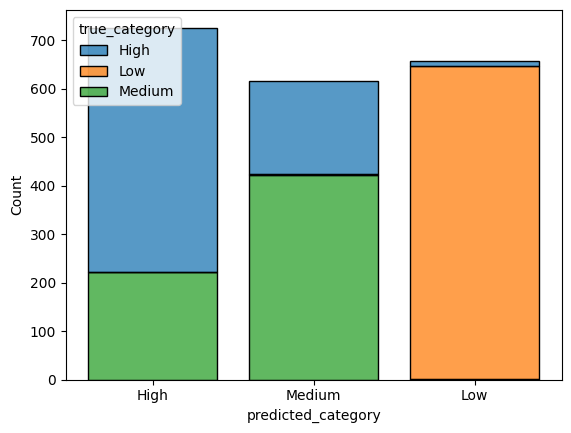

In [ ]:
(sns.histplot(data=df, x='predicted_category', hue='true_category', multiple='stack', shrink=0.8))

In [ ]:
def test_n_samples(n_sample, seed=42):
    np.random.seed(seed)
    samples_high = data[data['ability']=='High'].sample(n_sample, random_state=seed)
    samples_low = data[data['ability']=='Low'].sample(n_sample, random_state=seed)
    samples_medium = data[data['ability']=='Medium'].sample(n_sample, random_state=seed)

    graphs_samples_high=[create_graph_from_data(x,embedding) for x in samples_high.instruction_with_intention]
    graphs_samples_low=[create_graph_from_data(x,embedding) for x in samples_low.instruction_with_intention]
    graphs_samples_medium=[create_graph_from_data(x,embedding) for x in samples_medium.instruction_with_intention]

    barycentre_high = createbary(graphs_samples_high)
    barycentre_low = createbary(graphs_samples_low)
    barycentre_medium = createbary(graphs_samples_medium)

    graphs_high_cat = [closest_barycentre(graph, [barycentre_low, barycentre_medium, barycentre_high])[0] for graph in graphs_high]
    graphs_low_cat = [closest_barycentre(graph, [barycentre_low, barycentre_medium, barycentre_high])[0] for graph in graphs_low]
    graphs_medium_cat = [closest_barycentre(graph, [barycentre_low, barycentre_medium, barycentre_high])[0] for graph in graphs_medium]

    data_high_cat = pd.DataFrame({'instruction_with_intention': labels_high, 'predicted_category': graphs_high_cat, 'true_category': ['High']*len(labels_high)})
    data_low_cat = pd.DataFrame({'instruction_with_intention': labels_low, 'predicted_category': graphs_low_cat, 'true_category': ['Low']*len(labels_low)})
    data_medium_cat = pd.DataFrame({'instruction_with_intention': labels_medium, 'predicted_category': graphs_medium_cat, 'true_category': ['Medium']*len(labels_medium)})
    df = pd.concat([data_high_cat, data_low_cat, data_medium_cat], ignore_index=True)

    error_rate = np.mean(df['predicted_category'] != df['true_category'])
    return error_rate

In [ ]:
def optimal_n_samples(max_n=20,seed=42):
    np.random.seed(seed)
    error_rates = []
    for n in range(1, max_n+1):
        error_rate = test_n_samples(n,seed=seed)
        error_rates.append(error_rate)
    optimal_n = np.argmin(error_rates) + 1  # +1 because index starts at 0
    return error_rates, optimal_n

In [ ]:
errors = np.zeros((100, 29))  # 100 seeds, 29 sample sizes
seeds = np.random.randint(0, 100000, size=100)
for i, seed in enumerate(seeds):
    np.random.seed(seed)
    e, optimal_n = optimal_n_samples(max_n=29, seed=seed)
    errors[i] = e

No
Arm Gesture (Right)
Arm Gesture (Right)
Head Nod Yes
Acknowledging
Arm Gesture (Right)
Head Nod Yes
Successfully imported 210 edges from matrix.
Successfully imported 175 edges from matrix.
Successfully imported 210 edges from matrix.
No
Arm Gesture (Right)
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Right)
Head Nod Yes
Nervously Look Around
Arm Gesture (Left)
Acknowledging
Acknowledging
Arm Gesture (Right)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
No
Arm Gesture (Right)
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Right)
Head Nod Yes
Nervously Look Around
Arm Gesture (Left)
Acknowledging
Looking Around
Arm Gesture (Right)
Head Nod Yes
Acknowledging
Arm Gesture (Right)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Successfully imported 210 ed

In [ ]:
pdf = pd.DataFrame([], columns=['seed','n_sample','error_rate'])
for i, seed in enumerate(seeds):
    for n in range(1, 30):
        pdf = pd.concat([pdf, pd.DataFrame({'seed':[seed], 'n_sample':[n], 'error_rate':[errors[i][n-1]]})], ignore_index=True)

C:\Users\lucie\AppData\Local\Temp\ipykernel_32708\1988882753.py:4: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pdf = pd.concat([pdf, pd.DataFrame({'seed':[seed], 'n_sample':[n], 'error_rate':[errors[i][n-1]]})], ignore_index=True)


In [ ]:
sns.lineplot(x='n_sample', y='error_rate', data=pdf, x_label='Number of Human rated', y_label='Error Rate', title='Error Rate vs Number of Samples')

NameError: name 'sns' is not defined